In [20]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [21]:
# Load the 'taxis' dataset
df = sns.load_dataset("taxis")


In [22]:
# Check for missing values
print(df.isnull().sum())


pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


In [23]:
# Impute missing values
# - Fill numerical columns with median or mean (e.g., 'delay' or similar if present)
for col in df.select_dtypes(include=[np.number]).columns:
  df[col] = df[col].fillna(df[col].median())

In [24]:
# - Fill categorical columns with mode
for col in df.select_dtypes(include=["object", "category"]).columns:
  df[col] = df[col].fillna(df[col].mode()[0] if not df[col].mode().empty else "Unknown")


C:\Users\Manju M\AppData\Local\Temp\ipykernel_19784\4033785432.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include=["object", "category"]).columns:


In [25]:
# Drop critical rows where key identifiers or primary values are missing and cannot be imputed
df.dropna(subset=["pickup", "fare", "pickup_borough"], inplace=True)

# Line Chart (Fare over Time)

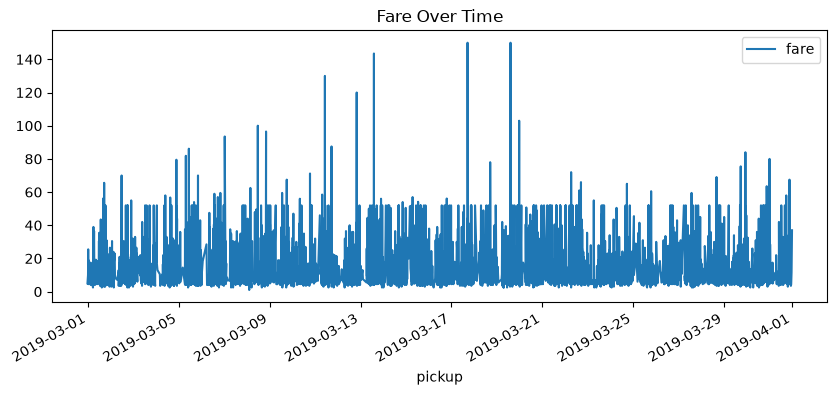

In [26]:
df["pickup"] = pd.to_datetime(df["pickup"])
df_sorted = df.sort_values("pickup")
df_sorted.plot(
    x="pickup", y="fare", kind="line", figsize=(10, 4), title="Fare Over Time"
)
plt.show()

# barchart


  borough_fares = df.groupby("pickup_borough")["fare"].sum()
  borough_fares.plot(kind="bar", title="Total Fare by Pickup Borough")
  plt.ylabel("Total Fare")
  plt.show()

# Pie Chart (Payment Method Distribution)

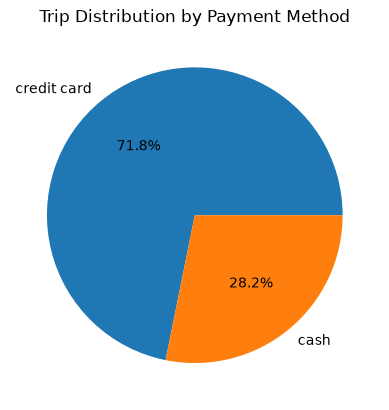

In [27]:
df["payment"].value_counts().plot(
    kind="pie", autopct="%1.1f%%", title="Trip Distribution by Payment Method"
)
plt.ylabel("")
plt.show()

# Histogram (Distance Distribution)

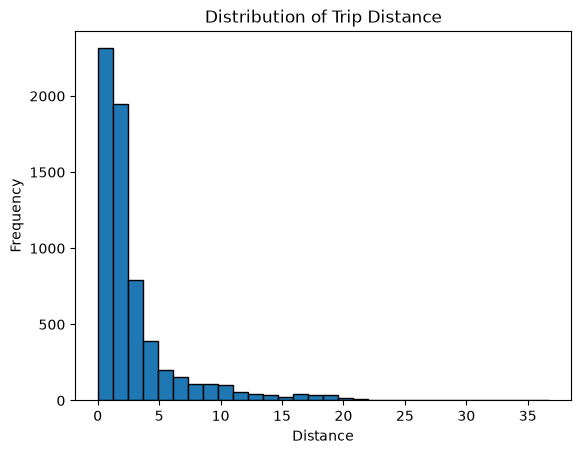

In [28]:

  plt.hist(df["distance"], bins=30, edgecolor="black")
  plt.title("Distribution of Trip Distance")
  plt.xlabel("Distance")
  plt.ylabel("Frequency")
  plt.show()

# boxplot

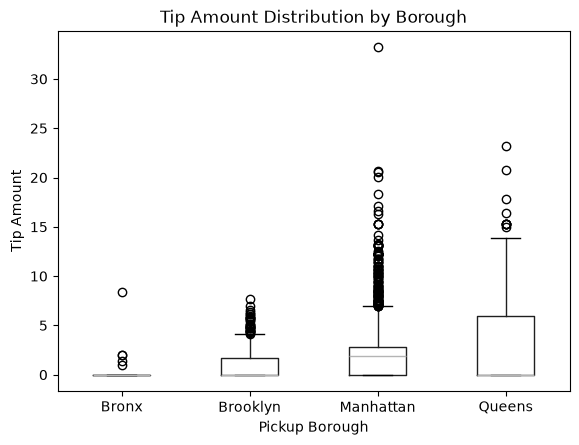

In [29]:
df.boxplot(column="tip", by="pickup_borough", grid=False)
plt.title("Tip Amount Distribution by Borough")
plt.suptitle("")  # Suppress default pandas suptitle
plt.xlabel("Pickup Borough")
plt.ylabel("Tip Amount")
plt.show()

# Visualizations using Seaborn

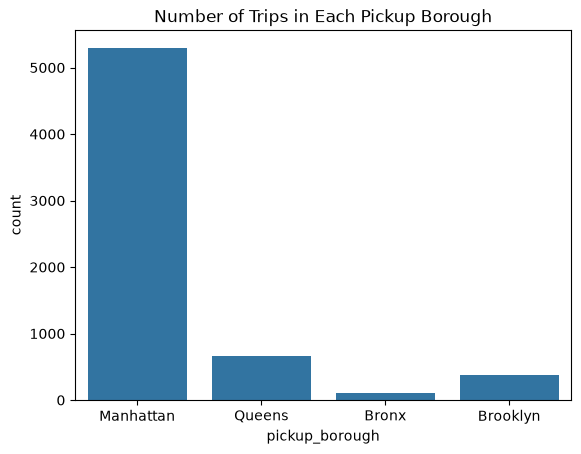

In [30]:
sns.countplot(data=df, x="pickup_borough")
plt.title("Number of Trips in Each Pickup Borough")
plt.show()


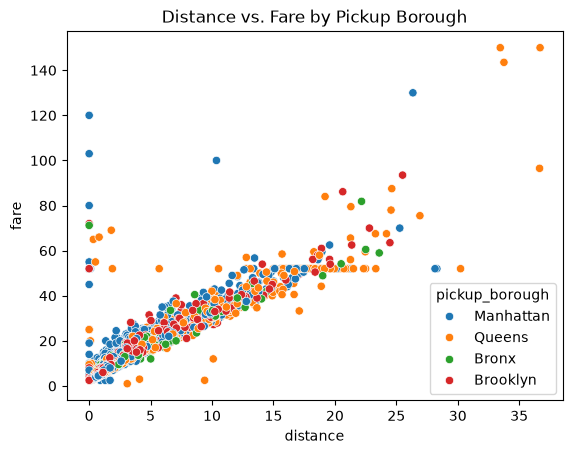

In [31]:
sns.scatterplot(data=df, x="distance", y="fare", hue="pickup_borough")
plt.title("Distance vs. Fare by Pickup Borough")
plt.show()

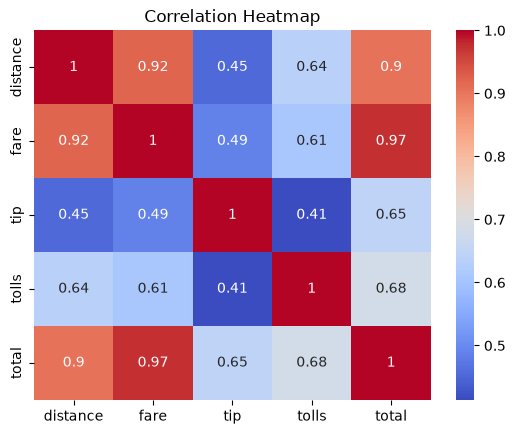

In [32]:
  num_cols = ["distance", "fare", "tip", "tolls", "total"]
  corr = df[num_cols].corr()
  sns.heatmap(corr, annot=True, cmap="coolwarm")
  plt.title("Correlation Heatmap")
  plt.show()

# pairplot

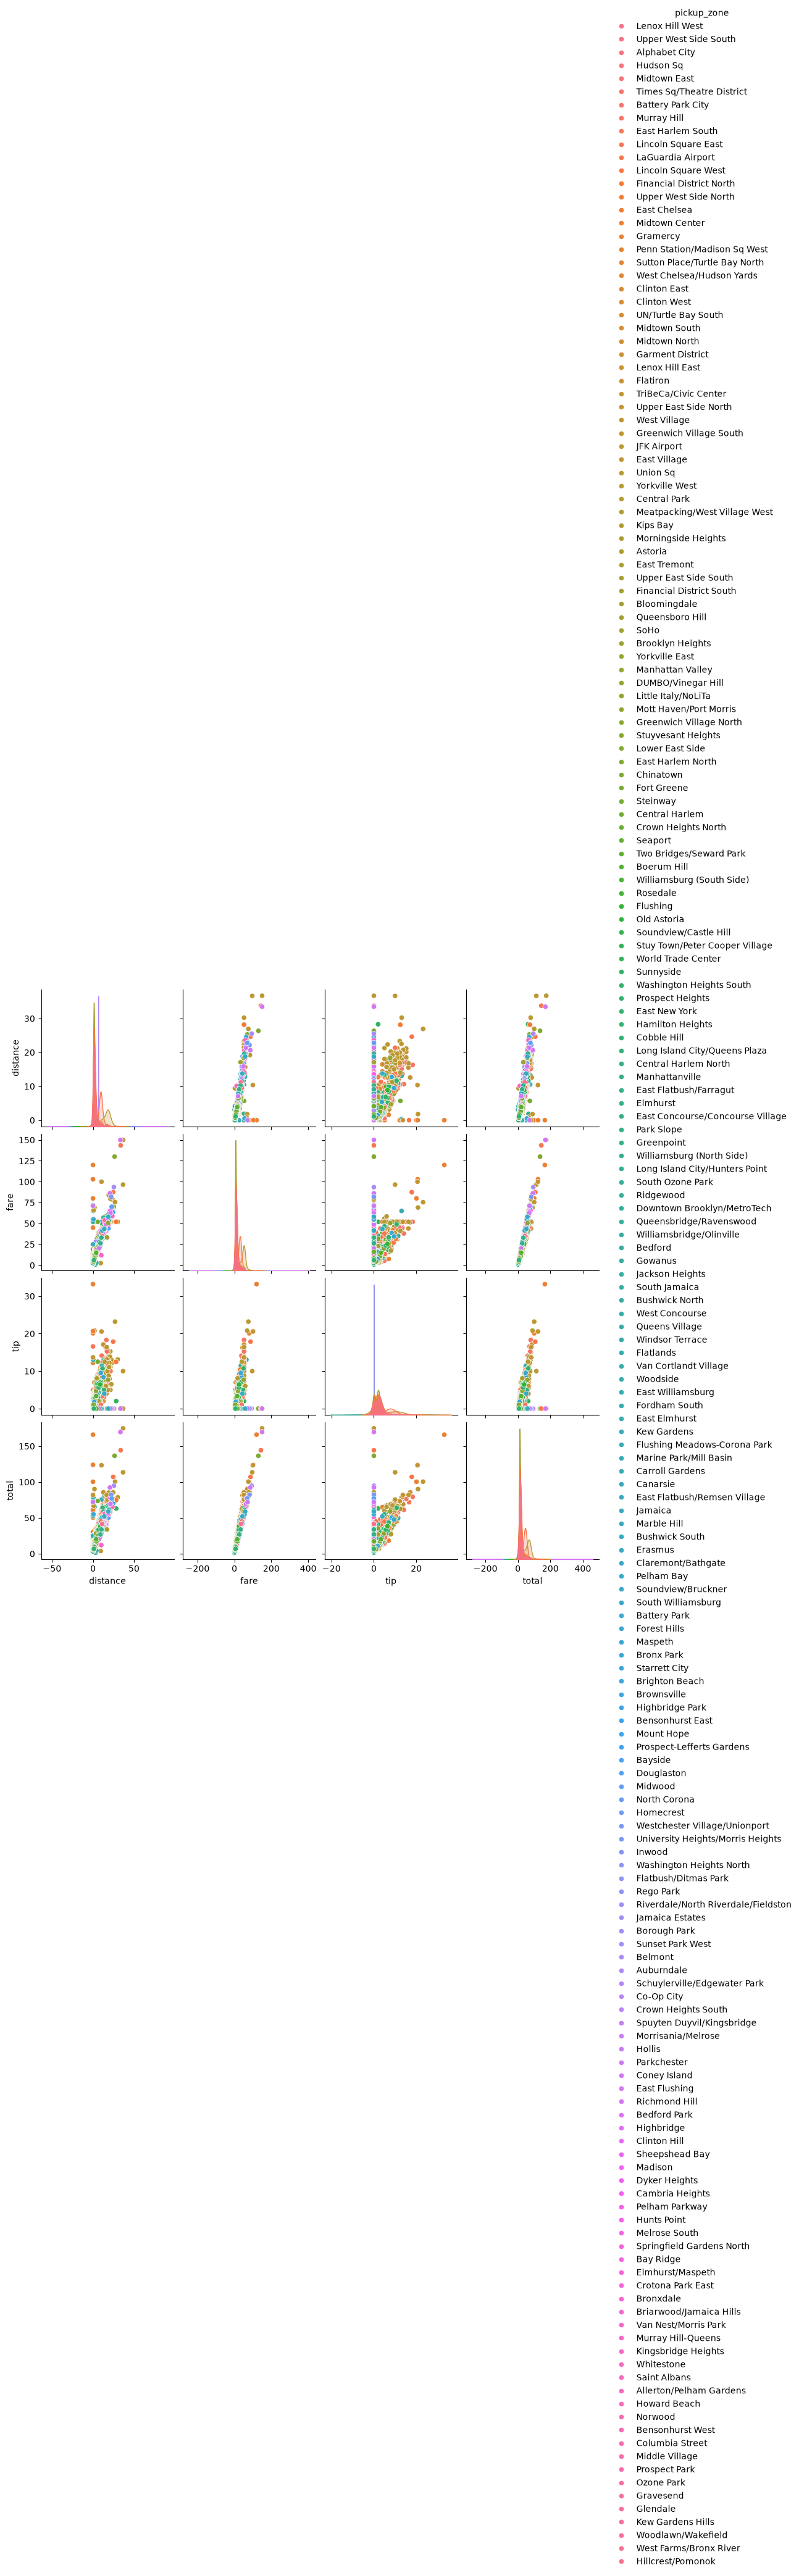

In [33]:
sns.pairplot(
    df,
    vars=["distance", "fare", "tip", "total"],
    hue="pickup_zone",
    diag_kind="kde",
)
plt.show()

# violin plot

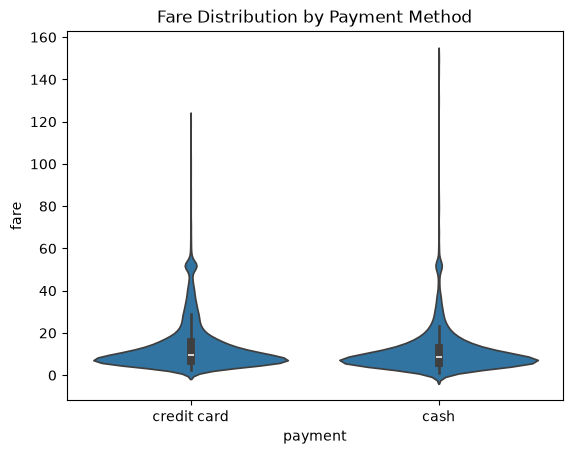

In [37]:
sns.violinplot(data=df, x="payment", y="fare")
plt.title("Fare Distribution by Payment Method")
plt.show()